## DATA WRANGLING
## Arquivo de apoio para estudo de data wrangling

In [29]:
# Processo de transformar a base de dados de sua estrutura original (dados brutos) para uma nova estrutura, mais adequada para extração de informações
# Envolve preparação, organização, manipulação do banco de dados
# Ocorre antes da análise exploratória dos dados, criação de dados e modelagem
# Quanto melhor o data wrangling, melhores serão os dados e maior a confiabilidade e consistência do banco de dados; logo, mais confiável a análise
# Não é uma etapa padronizada; diferentes etapas serão aplicadas, a depender do contexto
# Etapas comuns: coleta de informações (XLSX, CSV, API, ERP, CRM consulta SQL, Parquet etc), junção e transformação (limpeza dos dados, criação
# e criação de variáveis, seleção de observações, agregações, resumos etc

In [30]:
## O Processo CRISP-DM

# CRISP-DM é um framework cíclico para projetos de ciência de dados, composto por 6 etapas:

# 1. **Business Understanding** – Entender o problema de negócio que queremos resolver.
# 2. **Data Understanding** – Explorar os dados disponíveis e identificar problemas ou padrões iniciais.
# 3. **Data Preparation** – Limpar, transformar e organizar os dados para a modelagem. *(Foco deste notebook)*
# 4. **Modeling** – Aplicar algoritmos e construir modelos preditivos.
# 5. **Evaluation** – Avaliar se o modelo atende aos objetivos do negócio.
# 6. **Deployment** – Colocar o modelo em produção para uso real.

# **Data Wrangling** se encaixa principalmente nas etapas de *Data Understanding* e *Data Preparation*, # que juntas costumam 
# consumir cerca de 80% do tempo em um projeto de dados.

In [31]:
# IMPORTAÇÃO DE BANCOS DE DADOS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# pip install xlrd # pacote dependência que read_excel usa para ler arquivos na extensão .xls

In [32]:
# Importando banco de dados
dados_tempo = pd.read_excel('(1.2) dataset_principal.xls')
dados_merge = pd.read_excel('(1.3) dataset_join.xls')

In [33]:
#Configurar para visualizar objetos no console - todas as colunas separadas
pd.set_option("display.max.columns",None)
print(dados_tempo)

     Estudante  Tempo para chegar à escola (minutos)  \
0     Gabriela                                    15   
1       Dalila                                    20   
2      Gustavo                                    20   
3      Letícia                                    40   
4  Luiz Ovídio                                    50   
5       Leonor                                    25   
6          Ana                                    10   
7      Antônio                                    55   
8        Júlia                                    35   
9      Mariana                                    30   

   Distância percorrida até a escola (quilômetros)  Quantidade de semáforos  \
0                                                8                        0   
1                                                6                        1   
2                                               15                        0   
3                                               20                 

In [34]:
# Recuperar os nomes das colunas
dados_tempo.columns

Index(['Estudante', 'Tempo para chegar à escola (minutos)',
       'Distância percorrida até a escola (quilômetros)',
       'Quantidade de semáforos', 'Período do dia', 'Perfil ao volante'],
      dtype='object')

In [35]:
#Função info - retorna informações do banco de dados
# df.rename(columns={"xx":"yy"}
dados_tempo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   Estudante                                        10 non-null     object
 1   Tempo para chegar à escola (minutos)             10 non-null     int64 
 2   Distância percorrida até a escola (quilômetros)  10 non-null     int64 
 3   Quantidade de semáforos                          10 non-null     int64 
 4   Período do dia                                   10 non-null     object
 5   Perfil ao volante                                10 non-null     object
dtypes: int64(3), object(3)
memory usage: 612.0+ bytes


In [36]:
# Função rename - utilizada para alterar nome das variáveis
# Esta função serve para definir o banco de dados atual a um novo banco de dados. Se quiser alterar os nomes do próprio banco de dados
# usar inplace = True
dados_tempo.rename(columns={"Estudante":"estudante","Tempo para chegar à escola (minutos)":"tempo","Distância percorrida até a escola (quilômetros)":"distancia",\
                           "Quantidade de semáforos":"semaforos","Período do dia":"periodo","Perfil ao volante":"perfil"},inplace=True)

In [37]:
# Para renomear usando a posição, pode-se utilizar df.columns[index]
dados_novo = dados_tempo.rename(columns={dados_tempo.columns[0]:"obs",dados_tempo.columns[1]:"temp",dados_tempo.columns[5]:"perf",dados_tempo.columns[2]:"dist",\
                                        dados_tempo.columns[3]:"semaforos"})

In [38]:
# Função .head(n=x) serve para retornar as x primeiras linhas
dados_novo.head(6)

,obs,temp,dist,semaforos,periodo,perf
0,Gabriela,15,8,0,Manhã,calmo
1,Dalila,20,6,1,Manhã,moderado
2,Gustavo,20,15,0,Manhã,moderado
3,Letícia,40,20,1,Tarde,agressivo
4,Luiz Ovídio,50,25,2,Tarde,agressivo
5,Leonor,25,11,1,Manhã,moderado


In [39]:
# Função .tail(n=x) serve para retornar as x últimas linhas
dados_novo.tail(5)

,obs,temp,dist,semaforos,periodo,perf
5,Leonor,25,11,1,Manhã,moderado
6,Ana,10,5,0,Manhã,calmo
7,Antônio,55,32,3,Tarde,calmo
8,Júlia,35,28,1,Manhã,moderado
9,Mariana,30,20,1,Manhã,moderado


In [40]:
# Para reescrever o mesmo objeto, pode-se utilizar o argumento inplace = True. A diferença para o anterior é que aqui estou alterando
# o próprio objeto ao invés de criar um novo 
dados_novo.rename(columns={"obs":"observacao","temp":"tempo"},inplace=True)

In [41]:
# Selecionando com base na posição
# usar a função iloc[linha, coluna]   use : para incluir todos os valores de linhas ou todos de colunas
dados_novo.iloc[3,]

observacao      Letícia
tempo                40
dist                 20
semaforos             1
periodo           Tarde
perf          agressivo
Name: 3, dtype: object

In [42]:
dados_novo.iloc[:,4]

0    Manhã
1    Manhã
2    Manhã
3    Tarde
4    Tarde
5    Manhã
6    Manhã
7    Tarde
8    Manhã
9    Manhã
Name: periodo, dtype: object

In [43]:
dados_novo.iloc[2:5,]

,observacao,tempo,dist,semaforos,periodo,perf
2,Gustavo,20,15,0,Manhã,moderado
3,Letícia,40,20,1,Tarde,agressivo
4,Luiz Ovídio,50,25,2,Tarde,agressivo


In [44]:
dados_novo.iloc[:,3:5]
# O índice sempre conta o anterior

,semaforos,periodo
0,0,Manhã
1,1,Manhã
2,0,Manhã
3,1,Tarde
4,2,Tarde
5,1,Manhã
6,0,Manhã
7,3,Tarde
8,1,Manhã
9,1,Manhã


In [45]:
dados_novo.iloc[2:4,3:5]

,semaforos,periodo
2,0,Manhã
3,1,Tarde


In [46]:
dados_novo.iloc[5,4]

'Manhã'

In [47]:
#Detalhar uma variável em específico pelo nome
var_tempo = dados_tempo["tempo"]

In [48]:
# É possível acessar uma variável usando dois métodos
# df["variavel"]
# df.variavel
dados_tempo["perfil"]
dados_tempo.perfil

0        calmo
1     moderado
2     moderado
3    agressivo
4    agressivo
5     moderado
6        calmo
7        calmo
8     moderado
9     moderado
Name: perfil, dtype: object

In [49]:
#Se for mais de uma variável, inserir o argumento como uma lista
dados_tempo[["tempo","perfil"]]

,tempo,perfil
0,15,calmo
1,20,moderado
2,20,moderado
3,40,agressivo
4,50,agressivo
5,25,moderado
6,10,calmo
7,55,calmo
8,35,moderado
9,30,moderado


In [50]:
# Para selecionar variáveis por meio de um início em comum
# df.loc[:,df.columns.str.startswith("name")]
dados_tempo.loc[:,dados_tempo.columns.str.startswith("per")]

,periodo,perfil
0,Manhã,calmo
1,Manhã,moderado
2,Manhã,moderado
3,Tarde,agressivo
4,Tarde,agressivo
5,Manhã,moderado
6,Manhã,calmo
7,Tarde,calmo
8,Manhã,moderado
9,Manhã,moderado


In [51]:
# Para selecionar variáveis por meio de um final comum
# df.loc[:,df.columns.str.endswith("name")]
dados_tempo.loc[:,dados_tempo.columns.str.endswith("o")]

,tempo,periodo
0,15,Manhã
1,20,Manhã
2,20,Manhã
3,40,Tarde
4,50,Tarde
5,25,Manhã
6,10,Manhã
7,55,Tarde
8,35,Manhã
9,30,Manhã


In [52]:
# Para adicionar uma variável a um dataset existente
# df["variavel_nova"] = lista
idade = pd.Series([25,30,22,28,27,40,42,35,31,29])
dados_novo["idade"] = idade
dados_novo.rename(columns={"Período do dia":"periodo"},inplace=True)
print (dados_novo)

    observacao  tempo  dist  semaforos periodo       perf  idade
0     Gabriela     15     8          0   Manhã      calmo     25
1       Dalila     20     6          1   Manhã   moderado     30
2      Gustavo     20    15          0   Manhã   moderado     22
3      Letícia     40    20          1   Tarde  agressivo     28
4  Luiz Ovídio     50    25          2   Tarde  agressivo     27
5       Leonor     25    11          1   Manhã   moderado     40
6          Ana     10     5          0   Manhã      calmo     42
7      Antônio     55    32          3   Tarde      calmo     35
8        Júlia     35    28          1   Manhã   moderado     31
9      Mariana     30    20          1   Manhã   moderado     29


In [53]:
# Adicionando linhas ao banco de dados
# Usar a função concat
# df_concat = pd.concat([df existente,df a ser concatenado]) #ATENÇÃO: O argumento é uma lista, atenção aos colchetes
# Se quiser reiniciar o índice, incluir .reset_index(drop=True)

# novo registro
nova_obs = pd.DataFrame({"periodo":["Tarde"],"observacao":["Roberto"],"tempo":[40]})

# concatenando tudo
dados_concat = pd.concat([dados_novo,nova_obs]).reset_index(drop = True)
print(dados_concat)

# Neste exemplo, observe que os valores faltantes entraram como Nan

     observacao  tempo  dist  semaforos periodo       perf  idade
0      Gabriela     15   8.0        0.0   Manhã      calmo   25.0
1        Dalila     20   6.0        1.0   Manhã   moderado   30.0
2       Gustavo     20  15.0        0.0   Manhã   moderado   22.0
3       Letícia     40  20.0        1.0   Tarde  agressivo   28.0
4   Luiz Ovídio     50  25.0        2.0   Tarde  agressivo   27.0
5        Leonor     25  11.0        1.0   Manhã   moderado   40.0
6           Ana     10   5.0        0.0   Manhã      calmo   42.0
7       Antônio     55  32.0        3.0   Tarde      calmo   35.0
8         Júlia     35  28.0        1.0   Manhã   moderado   31.0
9       Mariana     30  20.0        1.0   Manhã   moderado   29.0
10      Roberto     40   NaN        NaN   Tarde        NaN    NaN


In [54]:
# Criar uma variável em função de outras duas
# No exemplo abaixo foi arredondado para duas casas decimais
# Lembrete: dados_novo["km"] cria uma variável nova
dados_novo["sem km"] = round((dados_novo["semaforos"]/dados_novo["dist"]),2)
print(dados_novo)

    observacao  tempo  dist  semaforos periodo       perf  idade  sem km
0     Gabriela     15     8          0   Manhã      calmo     25    0.00
1       Dalila     20     6          1   Manhã   moderado     30    0.17
2      Gustavo     20    15          0   Manhã   moderado     22    0.00
3      Letícia     40    20          1   Tarde  agressivo     28    0.05
4  Luiz Ovídio     50    25          2   Tarde  agressivo     27    0.08
5       Leonor     25    11          1   Manhã   moderado     40    0.09
6          Ana     10     5          0   Manhã      calmo     42    0.00
7      Antônio     55    32          3   Tarde      calmo     35    0.09
8        Júlia     35    28          1   Manhã   moderado     31    0.04
9      Mariana     30    20          1   Manhã   moderado     29    0.05


In [55]:
# Trocar rótulo de determinadas variáveis
# Usar a função "assign", que adiciona variáveis ao dataset, e a função "map", que aplica uma função a todos os elementos da lista

# Criar dicionário com labels
labels = {"calmo":"perfil_A","moderado":"perfil_B","agressivo":"perfil_C"}

df_labels = dados_tempo.assign(novo_perfil = dados_tempo.perfil.map(labels)) # criei a nova variável novo_perfil por segurança, para rastreabilidade e por
# exigência da função "assign"
df_labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   estudante    10 non-null     object
 1   tempo        10 non-null     int64 
 2   distancia    10 non-null     int64 
 3   semaforos    10 non-null     int64 
 4   periodo      10 non-null     object
 5   perfil       10 non-null     object
 6   novo_perfil  10 non-null     object
dtypes: int64(3), object(4)
memory usage: 692.0+ bytes


In [57]:
dados_tempo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   estudante  10 non-null     object
 1   tempo      10 non-null     int64 
 2   distancia  10 non-null     int64 
 3   semaforos  10 non-null     int64 
 4   periodo    10 non-null     object
 5   perfil     10 non-null     object
dtypes: int64(3), object(3)
memory usage: 612.0+ bytes


In [58]:
# Trocando dados por números
numeros = {"calmo":1,"moderado":2,"agressivo":3}
df_numeros = dados_tempo.assign(novo_perfil = dados_tempo["perfil"].map(numeros))
print(df_numeros)

     estudante  tempo  distancia  semaforos periodo     perfil  novo_perfil
0     Gabriela     15          8          0   Manhã      calmo            1
1       Dalila     20          6          1   Manhã   moderado            2
2      Gustavo     20         15          0   Manhã   moderado            2
3      Letícia     40         20          1   Tarde  agressivo            3
4  Luiz Ovídio     50         25          2   Tarde  agressivo            3
5       Leonor     25         11          1   Manhã   moderado            2
6          Ana     10          5          0   Manhã      calmo            1
7      Antônio     55         32          3   Tarde      calmo            1
8        Júlia     35         28          1   Manhã   moderado            2
9      Mariana     30         20          1   Manhã   moderado            2


In [59]:
# Trocando textos por números
textos = {0:"zero",1:"um",2:"dois",3:"tres"}
dados_texto = dados_tempo.assign(novo_texto = dados_tempo.semaforos.map(textos))
dados_texto

,estudante,tempo,distancia,semaforos,periodo,perfil,novo_texto
0,Gabriela,15,8,0,Manhã,calmo,zero
1,Dalila,20,6,1,Manhã,moderado,um
2,Gustavo,20,15,0,Manhã,moderado,zero
3,Letícia,40,20,1,Tarde,agressivo,um
4,Luiz Ovídio,50,25,2,Tarde,agressivo,dois
5,Leonor,25,11,1,Manhã,moderado,um
6,Ana,10,5,0,Manhã,calmo,zero
7,Antônio,55,32,3,Tarde,calmo,tres
8,Júlia,35,28,1,Manhã,moderado,um
9,Mariana,30,20,1,Manhã,moderado,um


In [60]:
# Categoriar aplicando critérios detalhados por meio de condições
dados_tempo["faixa"] = np.where(dados_tempo["tempo"]<=20,"rápido",np.where((dados_tempo["tempo"]>20)&(dados_tempo["tempo"]<40),"médio",\
                                                                           np.where(dados_tempo["tempo"]>40,"rápido","demais")))
dados_tempo

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa
0,Gabriela,15,8,0,Manhã,calmo,rápido
1,Dalila,20,6,1,Manhã,moderado,rápido
2,Gustavo,20,15,0,Manhã,moderado,rápido
3,Letícia,40,20,1,Tarde,agressivo,demais
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido
5,Leonor,25,11,1,Manhã,moderado,médio
6,Ana,10,5,0,Manhã,calmo,rápido
7,Antônio,55,32,3,Tarde,calmo,rápido
8,Júlia,35,28,1,Manhã,moderado,médio
9,Mariana,30,20,1,Manhã,moderado,médio


In [61]:
# Categorizar por meio de quartis
# função .qcut (informar quantos quartis q)
dados_tempo["quartis"]=pd.qcut(dados_tempo["tempo"],q=4,labels=[1,2,3,4])
dados_tempo

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [62]:
# Alterar o tipo de variável
# função astype()
# df[var] = df[var].astype("category")
df_numeros["novo_perfil"] = df_numeros["novo_perfil"].astype("category")
df_numeros.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   estudante    10 non-null     object  
 1   tempo        10 non-null     int64   
 2   distancia    10 non-null     int64   
 3   semaforos    10 non-null     int64   
 4   periodo      10 non-null     object  
 5   perfil       10 non-null     object  
 6   novo_perfil  10 non-null     category
dtypes: category(1), int64(3), object(3)
memory usage: 754.0+ bytes


In [65]:
# Excluir colunas sem uso
# .drop()   e .inplace=True

df_numeros.drop(columns=["periodo","perfil"],inplace=True)

In [66]:
df_numeros.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   estudante    10 non-null     object  
 1   tempo        10 non-null     int64   
 2   distancia    10 non-null     int64   
 3   semaforos    10 non-null     int64   
 4   novo_perfil  10 non-null     category
dtypes: category(1), int64(3), object(1)
memory usage: 594.0+ bytes


In [67]:
# Organização por critério
# sort_values(by=[var],ascending=True/False)
# reset_index(drop=True) redefine o índice após a ordenação
df_org_1 = dados_tempo.sort_values(by=["tempo"],ascending=True).reset_index(drop=True)
df_org_1

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Ana,10,5,0,Manhã,calmo,rápido,1
1,Gabriela,15,8,0,Manhã,calmo,rápido,1
2,Dalila,20,6,1,Manhã,moderado,rápido,1
3,Gustavo,20,15,0,Manhã,moderado,rápido,1
4,Leonor,25,11,1,Manhã,moderado,médio,2
5,Mariana,30,20,1,Manhã,moderado,médio,3
6,Júlia,35,28,1,Manhã,moderado,médio,3
7,Letícia,40,20,1,Tarde,agressivo,demais,4
8,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
9,Antônio,55,32,3,Tarde,calmo,rápido,4


In [68]:
df_org_2 = dados_tempo.sort_values(by=["distancia"],ascending=False).reset_index(drop=True)
df_org_2

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Antônio,55,32,3,Tarde,calmo,rápido,4
1,Júlia,35,28,1,Manhã,moderado,médio,3
2,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Mariana,30,20,1,Manhã,moderado,médio,3
5,Gustavo,20,15,0,Manhã,moderado,rápido,1
6,Leonor,25,11,1,Manhã,moderado,médio,2
7,Gabriela,15,8,0,Manhã,calmo,rápido,1
8,Dalila,20,6,1,Manhã,moderado,rápido,1
9,Ana,10,5,0,Manhã,calmo,rápido,1


In [69]:
# Possível organizar variáveis de texto
df_org_3 = dados_tempo.sort_values(by=["estudante"],ascending=True).reset_index(drop=True)
df_org_3

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Ana,10,5,0,Manhã,calmo,rápido,1
1,Antônio,55,32,3,Tarde,calmo,rápido,4
2,Dalila,20,6,1,Manhã,moderado,rápido,1
3,Gabriela,15,8,0,Manhã,calmo,rápido,1
4,Gustavo,20,15,0,Manhã,moderado,rápido,1
5,Júlia,35,28,1,Manhã,moderado,médio,3
6,Leonor,25,11,1,Manhã,moderado,médio,2
7,Letícia,40,20,1,Tarde,agressivo,demais,4
8,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [70]:
df_org_4 = dados_tempo.sort_values(by=["perfil"],ascending=False).reset_index(drop=True)
df_org_4

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Dalila,20,6,1,Manhã,moderado,rápido,1
1,Gustavo,20,15,0,Manhã,moderado,rápido,1
2,Leonor,25,11,1,Manhã,moderado,médio,2
3,Júlia,35,28,1,Manhã,moderado,médio,3
4,Mariana,30,20,1,Manhã,moderado,médio,3
5,Gabriela,15,8,0,Manhã,calmo,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Letícia,40,20,1,Tarde,agressivo,demais,4
9,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4


In [71]:
# Possível incluir mais de um critério
# usar listas para informar by e ascending
df_org_5 = dados_tempo.sort_values(by=["estudante","perfil"],ascending=[True,False]).reset_index(drop=True)
df_org_5

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Ana,10,5,0,Manhã,calmo,rápido,1
1,Antônio,55,32,3,Tarde,calmo,rápido,4
2,Dalila,20,6,1,Manhã,moderado,rápido,1
3,Gabriela,15,8,0,Manhã,calmo,rápido,1
4,Gustavo,20,15,0,Manhã,moderado,rápido,1
5,Júlia,35,28,1,Manhã,moderado,médio,3
6,Leonor,25,11,1,Manhã,moderado,médio,2
7,Letícia,40,20,1,Tarde,agressivo,demais,4
8,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
9,Mariana,30,20,1,Manhã,moderado,médio,3


## Visualizando estatísticas descritivas

In [73]:
## Função describe() - resumo estatístico de uma determinada variável
dados_tempo['tempo'].describe()

count    10.00000
mean     30.00000
std      14.90712
min      10.00000
25%      20.00000
50%      27.50000
75%      38.75000
max      55.00000
Name: tempo, dtype: float64

## Funções específicas para estatísticas individuais

In [74]:
# Média
dados_tempo["tempo"].mean()

30.0

In [76]:
# Contagem
dados_tempo["tempo"].count()

10

In [77]:
# Mediana
dados_tempo["tempo"].median()

27.5

In [78]:
# Mínimo
dados_tempo.min()

estudante          Ana
tempo               10
distancia            5
semaforos            0
periodo          Manhã
perfil       agressivo
faixa           demais
quartis              1
dtype: object

In [79]:
# Máximo
dados_tempo["tempo"].max()

55

In [80]:
# Desvio padrão
dados_tempo["tempo"].std()

14.907119849998598

In [81]:
# Variância
dados_tempo["tempo"].var()

222.22222222222223

In [87]:
# Quartis
dados_tempo["tempo"].quantile([0.25,0.5,0.75])

0.25    20.00
0.50    27.50
0.75    38.75
Name: tempo, dtype: float64

In [88]:
# Soma
dados_tempo["tempo"].sum()

300

In [90]:
# Correlação
dados_tempo[["tempo","distancia"]].corr()

,tempo,distancia
tempo,1.000000,0.905221
distancia,0.905221,1.000000


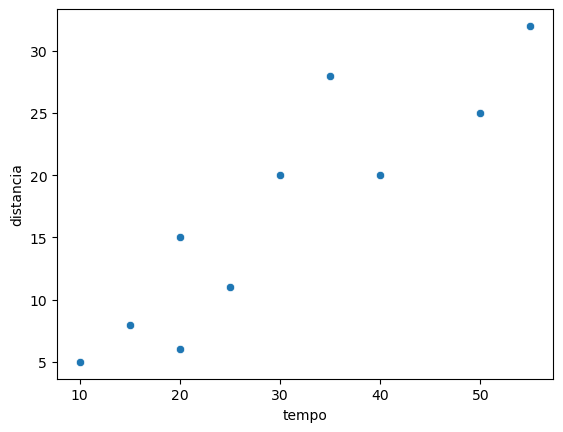

In [91]:
sns.scatterplot(dados_tempo,x = "tempo",y="distancia")
plt.show()

In [99]:
dados_tempo[["distancia","semaforos"]].corr()

,distancia,semaforos
distancia,1.000000,0.755914
semaforos,0.755914,1.000000


<Axes: xlabel='distancia', ylabel='semaforos'>

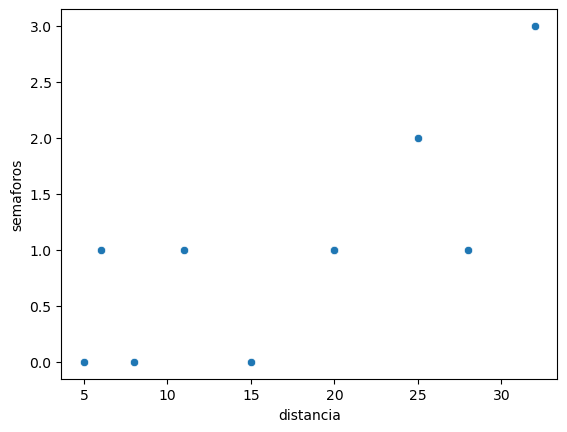

In [98]:
sns.scatterplot(dados_tempo,x="distancia",y="semaforos")

In [97]:
dados_tempo[["tempo","distancia","semaforos"]].corr()

,tempo,distancia,semaforos
tempo,1.000000,0.905221,0.909155
distancia,0.905221,1.000000,0.755914
semaforos,0.909155,0.755914,1.000000


In [ ]:
# Tabela de frequências para variáveis qualitativas
# value_counts() #frequências absolutas - o valor bruto, quantas vezes apareceu
# value_counts(normalize=True) #frequências relativas - o valor bruto dividido pela contagem, representa o %

In [102]:
dados_tempo["periodo"].value_counts()

periodo
Manhã    7
Tarde    3
Name: count, dtype: int64

In [103]:
dados_tempo["perfil"].value_counts(normalize=True)

perfil
moderado     0.5
calmo        0.3
agressivo    0.2
Name: proportion, dtype: float64

In [107]:
# Dados cruzados
# função pd.crosstab - cria uma tabulação cruzada de duas variáveis
# Se usar o argumento normalize=True, fará a comparação relativa
pd.crosstab(dados_tempo["periodo"],dados_tempo["perfil"])

perfil,agressivo,calmo,moderado
periodo,,,
Manhã,0,2,5
Tarde,2,1,0


In [111]:
pd.crosstab(dados_tempo["perfil"],dados_tempo["periodo"])

periodo,Manhã,Tarde
perfil,,
agressivo,0,2
calmo,2,1
moderado,5,0


In [112]:
pd.crosstab(dados_tempo["periodo"],dados_tempo["perfil"],normalize=True)

perfil,agressivo,calmo,moderado
periodo,,,
Manhã,0.0,0.2,0.5
Tarde,0.2,0.1,0.0


In [113]:
pd.crosstab(dados_tempo["perfil"],dados_tempo["periodo"],normalize=True)

periodo,Manhã,Tarde
perfil,,
agressivo,0.0,0.2
calmo,0.2,0.1
moderado,0.5,0.0


In [114]:
# Obtendo valores únicos de uma variável
dados_tempo["tempo"].unique()

array([15, 20, 40, 50, 25, 10, 55, 35, 30], dtype=int64)

In [116]:
dados_tempo["tempo"].nunique() #quantidade de valores únicos

9

In [123]:
# Criar um banco de dados agrupados em um critério 
#função .groupby(argumento")
dados_periodo = dados_tempo.groupby(["periodo"])

In [120]:
dados_periodo.describe()

tempo                                                    distancia  \
        count       mean       std   min   25%   50%   75%   max     count   
periodo                                                                      
Manhã     7.0  22.142857  8.591247  10.0  17.5  20.0  27.5  35.0       7.0   
Tarde     3.0  48.333333  7.637626  40.0  45.0  50.0  52.5  55.0       3.0   

                                                           semaforos  \
              mean       std   min   25%   50%   75%   max     count   
periodo                                                                
Manhã    13.285714  8.360907   5.0   7.0  11.0  17.5  28.0       7.0   
Tarde    25.666667  6.027714  20.0  22.5  25.0  28.5  32.0       3.0   

                                                      
             mean       std  min  25%  50%  75%  max  
periodo                                               
Manhã    0.571429  0.534522  0.0  0.0  1.0  1.0  1.0  
Tarde    2.000000  1.000000  1.0  1.5  2.0  2.5  3.0

In [125]:
# Para facilitar a visualização, use .T para transpor
dados_periodo.describe().T

periodo              Manhã      Tarde
tempo     count   7.000000   3.000000
          mean   22.142857  48.333333
          std     8.591247   7.637626
          min    10.000000  40.000000
          25%    17.500000  45.000000
          50%    20.000000  50.000000
          75%    27.500000  52.500000
          max    35.000000  55.000000
distancia count   7.000000   3.000000
          mean   13.285714  25.666667
          std     8.360907   6.027714
          min     5.000000  20.000000
          25%     7.000000  22.500000
          50%    11.000000  25.000000
          75%    17.500000  28.500000
          max    28.000000  32.000000
semaforos count   7.000000   3.000000
          mean    0.571429   2.000000
          std     0.534522   1.000000
          min     0.000000   1.000000
          25%     0.000000   1.500000
          50%     1.000000   2.000000
          75%     1.000000   2.500000
          max     1.000000   3.000000

In [126]:
dados_periodo.size()

periodo
Manhã    7
Tarde    3
dtype: int64

In [127]:
dados_tempo

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [130]:
# Criando agrupamento por mais de um critério
dados_criterios = dados_tempo.groupby(["periodo","perfil"])

In [132]:
dados_criterios.describe().T

periodo              Manhã                 Tarde      
perfil               calmo   moderado  agressivo calmo
tempo     count   2.000000   5.000000   2.000000   1.0
          mean   12.500000  26.000000  45.000000  55.0
          std     3.535534   6.519202   7.071068   NaN
          min    10.000000  20.000000  40.000000  55.0
          25%    11.250000  20.000000  42.500000  55.0
          50%    12.500000  25.000000  45.000000  55.0
          75%    13.750000  30.000000  47.500000  55.0
          max    15.000000  35.000000  50.000000  55.0
distancia count   2.000000   5.000000   2.000000   1.0
          mean    6.500000  16.000000  22.500000  32.0
          std     2.121320   8.455767   3.535534   NaN
          min     5.000000   6.000000  20.000000  32.0
          25%     5.750000  11.000000  21.250000  32.0
          50%     6.500000  15.000000  22.500000  32.0
          75%     7.250000  20.000000  23.750000  32.0
          max     8.000000  28.000000  25.000000  32.0
semaforos count   2.000000   5.000000   2.000000   1.0
          mean    0.000000   0.800000   1.500000   3.0
          std     0.000000   0.447214   0.707107   NaN
          min     0.000000   0.000000   1.000000   3.0
          25%     0.000000   1.000000   1.250000   3.0
          50%     0.000000   1.000000   1.500000   3.0
          75%     0.000000   1.000000   1.750000   3.0
          max     0.000000   1.000000   2.000000   3.0

In [135]:
dados_criterios = dados_tempo.groupby(["perfil","periodo"])
dados_criterios.describe().T

perfil           agressivo      calmo         moderado
periodo              Tarde      Manhã Tarde      Manhã
tempo     count   2.000000   2.000000   1.0   5.000000
          mean   45.000000  12.500000  55.0  26.000000
          std     7.071068   3.535534   NaN   6.519202
          min    40.000000  10.000000  55.0  20.000000
          25%    42.500000  11.250000  55.0  20.000000
          50%    45.000000  12.500000  55.0  25.000000
          75%    47.500000  13.750000  55.0  30.000000
          max    50.000000  15.000000  55.0  35.000000
distancia count   2.000000   2.000000   1.0   5.000000
          mean   22.500000   6.500000  32.0  16.000000
          std     3.535534   2.121320   NaN   8.455767
          min    20.000000   5.000000  32.0   6.000000
          25%    21.250000   5.750000  32.0  11.000000
          50%    22.500000   6.500000  32.0  15.000000
          75%    23.750000   7.250000  32.0  20.000000
          max    25.000000   8.000000  32.0  28.000000
semaforos count   2.000000   2.000000   1.0   5.000000
          mean    1.500000   0.000000   3.0   0.800000
          std     0.707107   0.000000   NaN   0.447214
          min     1.000000   0.000000   3.0   0.000000
          25%     1.250000   0.000000   3.0   1.000000
          50%     1.500000   0.000000   3.0   1.000000
          75%     1.750000   0.000000   3.0   1.000000
          max     2.000000   0.000000   3.0   1.000000

In [137]:
dados_criterios.size()

perfil     periodo
agressivo  Tarde      2
calmo      Manhã      2
           Tarde      1
moderado   Manhã      5
dtype: int64

In [138]:
dados_tempo

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [142]:
# Filtro de observações
# É possível usar df[df[var] == "valor"]
# ou
# é possível usar a função .query
filtro_calmo = dados_texto[dados_tempo["perfil"]=="calmo"]
filtro_calmo

,estudante,tempo,distancia,semaforos,periodo,perfil,novo_texto
0,Gabriela,15,8,0,Manhã,calmo,zero
6,Ana,10,5,0,Manhã,calmo,zero
7,Antônio,55,32,3,Tarde,calmo,tres


In [144]:
dados_texto.query("perfil == 'calmo'")

,estudante,tempo,distancia,semaforos,periodo,perfil,novo_texto
0,Gabriela,15,8,0,Manhã,calmo,zero
6,Ana,10,5,0,Manhã,calmo,zero
7,Antônio,55,32,3,Tarde,calmo,tres


In [150]:
dados_tempo.query("quartis == 1")

C:\Users\Bruno\AppData\Local\Temp\ipykernel_24756\3599107144.py:1: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  dados_tempo.query("quartis == 1")


,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1


In [157]:
dados_tempo[dados_tempo["quartis"] == 1]

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1


In [161]:
# Inserção entre critérios
# use &
# ATENÇÃO ÀS ASPAS SIMPLES E DUPLAS
dados_tempo.query("perfil == 'calmo' & periodo == 'Tarde'")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
7,Antônio,55,32,3,Tarde,calmo,rápido,4


In [162]:
dados_tempo.query("periodo == 'Manhã' & perfil == 'calmo'")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1


In [163]:
dados_tempo.query("faixa == 'rápido' & perfil == 'calmo' ")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4


In [164]:
# União entre critérios
# Use |
dados_tempo.query("perfil == 'calmo' | faixa == 'rápido'")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4


In [165]:
# Critério de diferente
# Use !=

dados_tempo.query("perfil != 'calmo'")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [87]:
# Utilizando operadores em variáveis métricas
dados_tempo.query("tempo >= 25")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [88]:
dados_tempo.query("tempo >= 25 & tempo < 40")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
5,Leonor,25,11,1,Manhã,moderado,médio,2
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [92]:
# inclusive: "both", "neither", "left" ou "right"
dados_tempo.query("tempo.between(20,40,inclusive='both')")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [101]:
# Comparar com valores de outro objeto
# usar a função isin()
nomes = pd.Series(["Gabriela","Gustavo","Leonor","Ana","Júlia"]) # criei uma série de nomes
filtro_contidos = dados_tempo[dados_tempo['estudante'].isin(nomes)]
filtro_contidos

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
8,Júlia,35,28,1,Manhã,moderado,médio,3


In [106]:
dados_tempo.query("estudante.isin(@nomes)")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
8,Júlia,35,28,1,Manhã,moderado,médio,3


In [108]:
# Usar o critério "não" ~ inverte o argumento
dados_tempo.query("~(tempo >= 25)")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
6,Ana,10,5,0,Manhã,calmo,rápido,1


In [109]:
dados_tempo.query("~(perfil == 'calmo')")

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [112]:
dados_tempo.query('~(estudante.isin(@nomes))')

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
1,Dalila,20,6,1,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
7,Antônio,55,32,3,Tarde,calmo,rápido,4
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [122]:
# Junção de um banco de dados
# Função pd.merge
# Exige uma variável em comum a todos os datasets
# Inicialmente, deixar as colunas chames com o mesmo nome nos dois datasets

#Renomear a coluna "Estudante" para "estudante"
dados_merge.rename(columns={"Estudante":"estudante"},inplace=True)
dados_merge

,estudante,Região_Cidade
0,Gabriela,Região_A
1,Dalila,Região_B
2,Letícia,Região_C
3,Leonor,Região_B
4,Ana,Região_A
5,Júlia,Região_C
6,Mariana,Região_C
7,Gustavo,Região_B
8,Luiz Ovídio,Região_D
9,Marcos,Região_D


In [130]:
# Parâmetros da função merge
# how: a direção do merge (quais IDs restam na base final)
    # left - somente os IDs do banco de dados à esquerda
    # right - somente os IDs do banco de dados à direita
    # outer - todos os IDs presentes nos bancos de dados
    # inner - somente os IDs que constam nos dois dois bancos de dados; intersecção
# on: coluna-chave para o merge

In [121]:
dados_tempo

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
0,Gabriela,15,8,0,Manhã,calmo,rápido,1
1,Dalila,20,6,1,Manhã,moderado,rápido,1
2,Gustavo,20,15,0,Manhã,moderado,rápido,1
3,Letícia,40,20,1,Tarde,agressivo,demais,4
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4
5,Leonor,25,11,1,Manhã,moderado,médio,2
6,Ana,10,5,0,Manhã,calmo,rápido,1
7,Antônio,55,32,3,Tarde,calmo,rápido,4
8,Júlia,35,28,1,Manhã,moderado,médio,3
9,Mariana,30,20,1,Manhã,moderado,médio,3


In [119]:
dados_merge

,estudante,Região_Cidade
0,Gabriela,Região_A
1,Dalila,Região_B
2,Letícia,Região_C
3,Leonor,Região_B
4,Ana,Região_A
5,Júlia,Região_C
6,Mariana,Região_C
7,Gustavo,Região_B
8,Luiz Ovídio,Região_D
9,Marcos,Região_D


In [125]:
merge_1 = pd.merge(dados_tempo,dados_merge,how="left",on="estudante")
merge_1

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis,Região_Cidade
0,Gabriela,15,8,0,Manhã,calmo,rápido,1,Região_A
1,Dalila,20,6,1,Manhã,moderado,rápido,1,Região_B
2,Gustavo,20,15,0,Manhã,moderado,rápido,1,Região_B
3,Letícia,40,20,1,Tarde,agressivo,demais,4,Região_C
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4,Região_D
5,Leonor,25,11,1,Manhã,moderado,médio,2,Região_B
6,Ana,10,5,0,Manhã,calmo,rápido,1,Região_A
7,Antônio,55,32,3,Tarde,calmo,rápido,4,NaN
8,Júlia,35,28,1,Manhã,moderado,médio,3,Região_C
9,Mariana,30,20,1,Manhã,moderado,médio,3,Região_C


In [127]:
merge_2 = pd.merge(dados_tempo,dados_merge,how="right",on="estudante")
merge_2

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis,Região_Cidade
0,Gabriela,15.0,8.0,0.0,Manhã,calmo,rápido,1,Região_A
1,Dalila,20.0,6.0,1.0,Manhã,moderado,rápido,1,Região_B
2,Letícia,40.0,20.0,1.0,Tarde,agressivo,demais,4,Região_C
3,Leonor,25.0,11.0,1.0,Manhã,moderado,médio,2,Região_B
4,Ana,10.0,5.0,0.0,Manhã,calmo,rápido,1,Região_A
5,Júlia,35.0,28.0,1.0,Manhã,moderado,médio,3,Região_C
6,Mariana,30.0,20.0,1.0,Manhã,moderado,médio,3,Região_C
7,Gustavo,20.0,15.0,0.0,Manhã,moderado,rápido,1,Região_B
8,Luiz Ovídio,50.0,25.0,2.0,Tarde,agressivo,rápido,4,Região_D
9,Marcos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Região_D


In [129]:
merge_3 = pd.merge(dados_tempo,dados_merge,how="outer",on="estudante")
merge_3

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis,Região_Cidade
0,Ana,10.0,5.0,0.0,Manhã,calmo,rápido,1,Região_A
1,Antônio,55.0,32.0,3.0,Tarde,calmo,rápido,4,NaN
2,Dalila,20.0,6.0,1.0,Manhã,moderado,rápido,1,Região_B
3,Gabriela,15.0,8.0,0.0,Manhã,calmo,rápido,1,Região_A
4,Gustavo,20.0,15.0,0.0,Manhã,moderado,rápido,1,Região_B
5,Júlia,35.0,28.0,1.0,Manhã,moderado,médio,3,Região_C
6,Leonor,25.0,11.0,1.0,Manhã,moderado,médio,2,Região_B
7,Letícia,40.0,20.0,1.0,Tarde,agressivo,demais,4,Região_C
8,Luiz Ovídio,50.0,25.0,2.0,Tarde,agressivo,rápido,4,Região_D
9,Marcos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Região_D


In [132]:
merge_4 = pd.merge(dados_tempo,dados_merge,on="estudante",how="inner")
merge_4

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis,Região_Cidade
0,Gabriela,15,8,0,Manhã,calmo,rápido,1,Região_A
1,Dalila,20,6,1,Manhã,moderado,rápido,1,Região_B
2,Gustavo,20,15,0,Manhã,moderado,rápido,1,Região_B
3,Letícia,40,20,1,Tarde,agressivo,demais,4,Região_C
4,Luiz Ovídio,50,25,2,Tarde,agressivo,rápido,4,Região_D
5,Leonor,25,11,1,Manhã,moderado,médio,2,Região_B
6,Ana,10,5,0,Manhã,calmo,rápido,1,Região_A
7,Júlia,35,28,1,Manhã,moderado,médio,3,Região_C
8,Mariana,30,20,1,Manhã,moderado,médio,3,Região_C


In [138]:
# Verificando apenas a diferença entre bancos de dados
merge_5 = dados_tempo[~dados_tempo["estudante"].isin(dados_merge["estudante"])]
merge_5

,estudante,tempo,distancia,semaforos,periodo,perfil,faixa,quartis
7,Antônio,55,32,3,Tarde,calmo,rápido,4
